# Inflation et chômage dans le monde (1991–2021) — préparation des données

SDS3786 · Rayane Slimane-Kadi, Mohamed Elsobky

Ce notebook présente, étape par étape, tout ce qui est fait avant le tableau de bord :

1. Chargement des trois sources
2. Analyse exploratoire des données brutes (AED) et problèmes rencontrés
3. Nettoyage : format long, retrait des agrégats, jointure
4. AED du jeu combiné
5. Imputation des valeurs manquantes
6. Regroupement des pays (KMeans)
7. Vérification : le notebook reproduit exactement la sortie de `prepare_data.py`

`prepare_data.py` reste le pipeline utilisé par le tableau de bord ; ce notebook en montre et justifie chaque étape.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RAW, CLEAN = Path("data/raw"), Path("data/clean")
YEARS = range(1991, 2022)  # période commune aux deux jeux (le chômage s'arrête en 2021)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 12)

## 1. Chargement des trois sources

| Jeu | Fichier | Apporte |
|---|---|---|
| JD1 – Unemployment dataset (Kaggle, Banque mondiale / OIT) | `unemployment analysis.csv` | Chômage (% de la population active) |
| JD2 – Global Inflation Dataset (Kaggle, Banque mondiale) | `Global Dataset of Inflation.csv` | Inflation globale, alimentaire, énergie… |
| JD3 – API Banque mondiale `/v2/country` | `countries.json` | Région et groupe de revenu de chaque pays |

In [2]:
unemp_raw = pd.read_csv(RAW / "unemployment analysis.csv", encoding="utf-8-sig")
infl_raw = pd.read_csv(RAW / "Global Dataset of Inflation.csv", encoding="latin-1")
meta_raw = pd.DataFrame(json.loads((RAW / "countries.json").read_text())[1])

for name, df in [("JD1 chômage", unemp_raw), ("JD2 inflation", infl_raw), ("JD3 métadonnées", meta_raw)]:
    print(f"{name:16} {df.shape[0]:4} lignes × {df.shape[1]:3} colonnes")

JD1 chômage       235 lignes ×  33 colonnes
JD2 inflation     783 lignes ×  64 colonnes
JD3 métadonnées   296 lignes ×  10 colonnes


In [3]:
unemp_raw.iloc[:5, :8]

,Country Name,Country Code,1991,1992,1993,1994,1995,1996
0,Africa Eastern and Southern,AFE,7.80,7.84,7.85,7.84,7.83,7.84
1,Afghanistan,AFG,10.65,10.82,10.72,10.73,11.18,10.96
2,Africa Western and Central,AFW,4.42,4.53,4.55,4.54,4.53,4.57
3,Angola,AGO,4.21,4.21,4.23,4.16,4.11,4.10
4,Albania,ALB,10.31,30.01,25.26,20.84,14.61,13.93


In [4]:
infl_raw.iloc[:5, :8]

,Country Code,IMF Country Code,Country,Indicator Type,Series Name,1970,1971,1972
0,ABW,314.0,Aruba,Inflation,Headline Consumer Price Inflation,NaN,NaN,NaN
1,AFG,512.0,Afghanistan,Inflation,Headline Consumer Price Inflation,25.51,25.51,-12.52
2,AGO,614.0,Angola,Inflation,Headline Consumer Price Inflation,7.97,5.78,15.80
3,ALB,914.0,Albania,Inflation,Headline Consumer Price Inflation,NaN,NaN,NaN
4,ARE,466.0,United Arab Emirates,Inflation,Headline Consumer Price Inflation,21.98,21.98,21.98


## 2. AED des données brutes : problèmes rencontrés

### 2.1 Encodage du fichier d'inflation
Lu en UTF-8, certains noms de pays sont illisibles ; le fichier est en réalité encodé en latin-1.

In [5]:
as_utf8 = pd.read_csv(RAW / "Global Dataset of Inflation.csv", encoding="utf-8", encoding_errors="replace")
print("UTF-8   :", sorted(as_utf8.loc[as_utf8.Country.str.contains("\ufffd"), "Country"].unique()))
print("latin-1 :", sorted(infl_raw.loc[infl_raw["Country Code"].isin(["CIV", "STP"]), "Country"].unique()))

UTF-8   : ["C�te d'Ivoire", 'S�o Tom� and Principe']
latin-1 : ["Côte d'Ivoire", 'São Tomé and Principe']


### 2.2 Colonnes inutiles du fichier d'inflation : une colonne constante et des colonnes vides

In [6]:
print("Valeurs de 'Indicator Type' :", infl_raw["Indicator Type"].unique())
print("Colonnes entièrement vides  :", [c for c in infl_raw.columns if infl_raw[c].isna().all()])

Valeurs de 'Indicator Type' : ['Inflation']
Colonnes entièrement vides  : ['Unnamed: 60', 'Unnamed: 61', 'Unnamed: 62', 'Unnamed: 63']


### 2.3 Agrégats mélangés aux pays dans le fichier de chômage
JD1 contient aussi des lignes « Monde », « Afrique subsaharienne », « Revenu élevé »… Les métadonnées (JD3) les marquent
comme `Aggregates`, ce qui permet de les retirer.

In [7]:
meta = pd.DataFrame({
    "iso3": meta_raw["id"],
    "region": meta_raw["region"].map(lambda r: r["value"].strip()),
    "income_group": meta_raw["incomeLevel"].map(lambda r: r["value"].strip()),
})
aggregates = set(meta.loc[meta.region == "Aggregates", "iso3"])
is_agg = unemp_raw["Country Code"].isin(aggregates)
print(f"{is_agg.sum()} agrégats dans JD1, par exemple :", unemp_raw.loc[is_agg, "Country Name"].head(6).tolist())
print("Codes de JD1 absents de JD3 :", sorted(set(unemp_raw["Country Code"]) - set(meta.iso3)))

47 agrégats dans JD1, par exemple : ['Africa Eastern and Southern', 'Africa Western and Central', 'Arab World', 'Central Europe and the Baltics', 'Caribbean small states', 'East Asia & Pacific (excluding high income)']
Codes de JD1 absents de JD3 : ['FCS']


### 2.4 Couverture et valeurs manquantes des séries d'inflation (1991–2021)
L'inflation sous-jacente et les prix à la production manquent pour 30 à 35 % des pays-années et ne servent à aucune
question du projet : on garde seulement les séries globale, alimentaire et énergie.

,pays,manquants (%)
Series Name,,
Headline Consumer Price Inflation,203,5.1
Food Consumer Price Inflation,182,10.5
Energy Consumer Price Inflation,172,18.7
Producer Price Inflation,113,30.0
Official Core Consumer Price Inflation,113,35.5


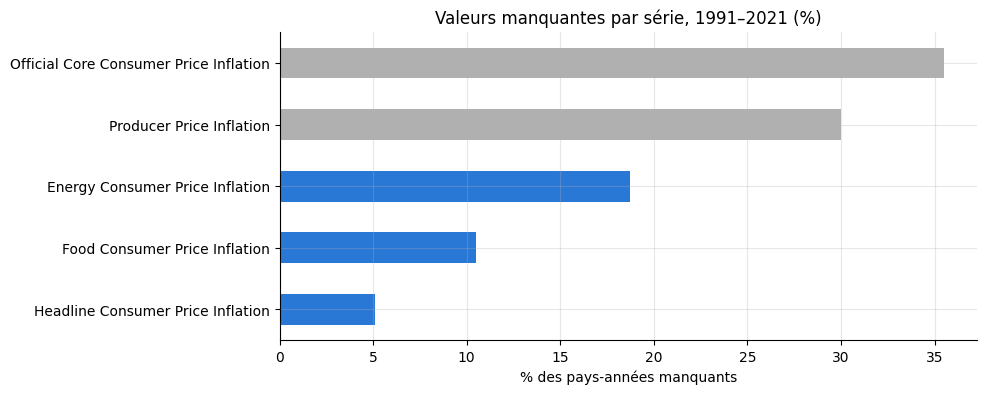

In [8]:
year_cols = [str(y) for y in YEARS]
by_series = infl_raw.set_index("Series Name")[year_cols]
summary = pd.DataFrame({
    "pays": infl_raw["Series Name"].value_counts(),
    "manquants (%)": by_series.isna().groupby(level=0).mean().mean(axis=1).mul(100).round(1),
}).sort_values("manquants (%)")
display(summary)

summary["manquants (%)"].plot.barh(color=["#2a78d6"] * 3 + ["#b0b0b0"] * 2, title="Valeurs manquantes par série, 1991–2021 (%)")
plt.xlabel("% des pays-années manquants"); plt.ylabel(""); plt.show()

## 3. Nettoyage : format long, jointure

Les deux fichiers sont en format large (une colonne par année). On les passe en format long (`melt`), une ligne par
pays × année, puis on les joint aux métadonnées sur le code ISO3.

In [9]:
SERIES = {"Headline Consumer Price Inflation": "inflation",
          "Food Consumer Price Inflation": "food_inflation",
          "Energy Consumer Price Inflation": "energy_inflation"}
INFL_COLS = list(SERIES.values())

# JD1 : large -> long
unemp = (unemp_raw.melt(id_vars=["Country Name", "Country Code"], var_name="year", value_name="unemployment")
         .rename(columns={"Country Name": "country", "Country Code": "iso3"})
         .astype({"year": int}))

# JD2 : 3 séries utiles, large -> long, puis une colonne par série
infl = (infl_raw[infl_raw["Series Name"].isin(SERIES)]
        .melt(id_vars=["Country Code", "Series Name"], value_vars=year_cols, var_name="year", value_name="value")
        .astype({"year": int})
        .pivot_table(index=["Country Code", "year"], columns="Series Name", values="value").reset_index()
        .rename(columns={"Country Code": "iso3", **SERIES}))

print("JD1 long :", unemp.shape, "| JD2 long :", infl.shape)
infl.head()

JD1 long : (7285, 4) | JD2 long : (5980, 5)


Series Name,iso3,year,energy_inflation,food_inflation,inflation
0,ABW,1996,NaN,NaN,3.20
1,ABW,1997,NaN,NaN,3.00
2,ABW,1998,NaN,NaN,1.88
3,ABW,1999,NaN,NaN,2.28
4,ABW,2000,NaN,NaN,4.05


In [10]:
REGIONS_FR = {
    "East Asia & Pacific": "Asie de l'Est et Pacifique", "Europe & Central Asia": "Europe et Asie centrale",
    "Latin America & Caribbean": "Amérique latine et Caraïbes",
    "Middle East & North Africa": "Moyen-Orient et Afrique du Nord",
    "Middle East, North Africa, Afghanistan & Pakistan": "Moyen-Orient et Afrique du Nord",
    "North America": "Amérique du Nord", "South Asia": "Asie du Sud", "Sub-Saharan Africa": "Afrique subsaharienne",
}
INCOME_FR = {"High income": "Revenu élevé", "Upper middle income": "Revenu intermédiaire supérieur",
             "Lower middle income": "Revenu intermédiaire inférieur", "Low income": "Faible revenu",
             "Not classified": "Non classé"}

countries = meta[meta.region != "Aggregates"].copy()          # retire les agrégats
countries["region"] = countries.region.map(REGIONS_FR)
countries["income_group"] = countries.income_group.map(INCOME_FR).fillna("Non classé")

# Pays présents dans les 3 sources : chômage + métadonnées, puis inflation (jointure gauche sur pays × année)
panel = unemp.merge(countries, on="iso3").merge(infl, on=["iso3", "year"], how="left")
panel = panel[panel.iso3.isin(infl.iso3)]

u, i = set(unemp.iso3) - aggregates, set(infl.iso3)
print(f"Pays communs : {panel.iso3.nunique()} | seulement dans JD2 : {len(i - u)} | seulement dans JD1 : {len(u - i - {'FCS'})}")
print("Exemples seulement dans JD2 :", sorted(infl_raw.loc[infl_raw['Country Code'].isin(i - u), 'Country'].unique())[:6])
print(f"Panel : {len(panel)} lignes, {panel.dropna(subset=['unemployment', 'inflation']).shape[0]} paires chômage-inflation complètes")

Pays communs : 180 | seulement dans JD2 : 21 | seulement dans JD1 : 7
Exemples seulement dans JD2 : ['Antigua and Barbuda', 'Aruba', 'British Virgin Islands', 'Cayman Islands', 'Curacao', 'Dominica']
Panel : 5580 lignes, 5489 paires chômage-inflation complètes


## 4. AED du jeu combiné

In [11]:
panel[['unemployment'] + INFL_COLS].describe().round(2)

,unemployment,inflation,food_inflation,energy_inflation
count,5580.00,5489.00,4849.00,4178.00
mean,8.26,52.41,35.99,45.34
std,6.41,1043.48,644.51,1499.21
min,0.10,-72.73,-34.40,-47.20
25%,3.73,1.86,1.60,1.27
50%,6.38,4.18,4.41,3.93
75%,11.00,9.03,9.80,8.88
max,38.80,65374.08,38386.00,94802.37


### 4.1 Distributions
Le chômage est asymétrique à droite (quelques pays au-dessus de 20 %). L'inflation l'est beaucoup plus : quelques
hyperinflations écrasent tout le reste, d'où l'échelle logarithmique ci-dessous.

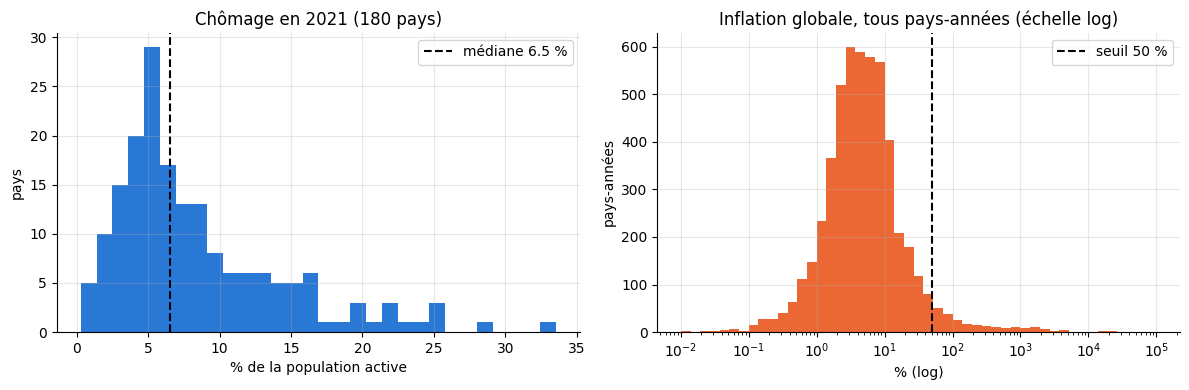

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
u21 = panel.loc[panel.year == 2021, "unemployment"]
a1.hist(u21, bins=30, color="#2a78d6")
a1.axvline(u21.median(), color="k", ls="--", label=f"médiane {u21.median():.1f} %")
a1.set(title="Chômage en 2021 (180 pays)", xlabel="% de la population active", ylabel="pays"); a1.legend()

pos = panel.inflation[panel.inflation > 0]
a2.hist(pos, bins=np.logspace(-2, 5, 50), color="#eb6834")
a2.set_xscale("log"); a2.axvline(50, color="k", ls="--", label="seuil 50 %")
a2.set(title="Inflation globale, tous pays-années (échelle log)", xlabel="% (log)", ylabel="pays-années"); a2.legend()
plt.tight_layout(); plt.show()

### 4.2 Valeurs extrêmes : les hyperinflations
Ces valeurs sont réelles (Venezuela, Zimbabwe, ex-URSS…), mais elles écrasent les graphiques et les corrélations.
Décision : les conserver dans les données, mais les masquer au-delà de 50 % par défaut dans le tableau de bord
(un interrupteur permet de les réinclure).

In [13]:
print(f"> 50 % : {(panel.inflation > 50).sum()} pays-années | > 100 % : {(panel.inflation > 100).sum()}")
panel.nlargest(8, "inflation")[["country", "year", "inflation", "unemployment"]]

> 50 % : 237 pays-années | > 100 % : 139


,country,year,inflation,unemployment
5227,"Venezuela, RB",2018,65374.08,5.02
595,"Congo, Dem. Rep.",1994,23773.10,2.92
5414,"Venezuela, RB",2019,19906.02,5.10
5568,Sudan,2020,17087.72,19.65
620,Georgia,1994,15606.50,8.40
566,Armenia,1994,5273.45,6.60
547,Ukraine,1993,4660.58,2.00
936,Angola,1996,4146.01,4.10


### 4.3 Valeurs manquantes par année

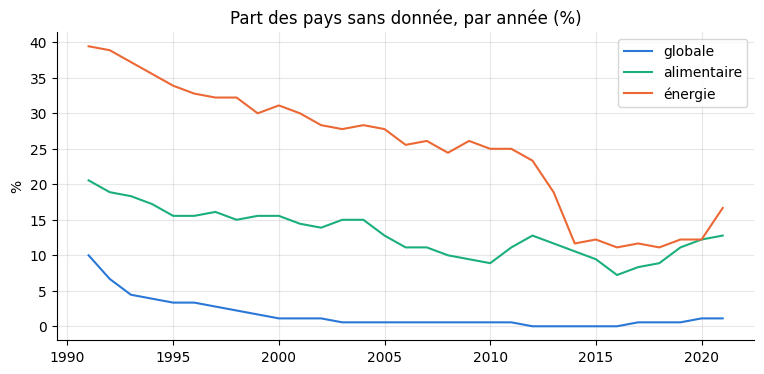

Chômage : aucune valeur manquante (estimations modélisées de l'OIT) -> 0


In [14]:
panel.groupby("year")[INFL_COLS].apply(lambda g: g.isna().mean() * 100).plot(
    title="Part des pays sans donnée, par année (%)", color=["#2a78d6", "#1baf7a", "#eb6834"])
plt.ylabel("%"); plt.xlabel(""); plt.legend(["globale", "alimentaire", "énergie"]); plt.show()
print("Chômage : aucune valeur manquante (estimations modélisées de l'OIT) ->", panel.unemployment.isna().sum())

### 4.4 Tendances mondiales et chocs
Le chômage médian bondit en 2020 (COVID-19) ; l'inflation médiane chute après les années 1990 puis remonte en 2021.

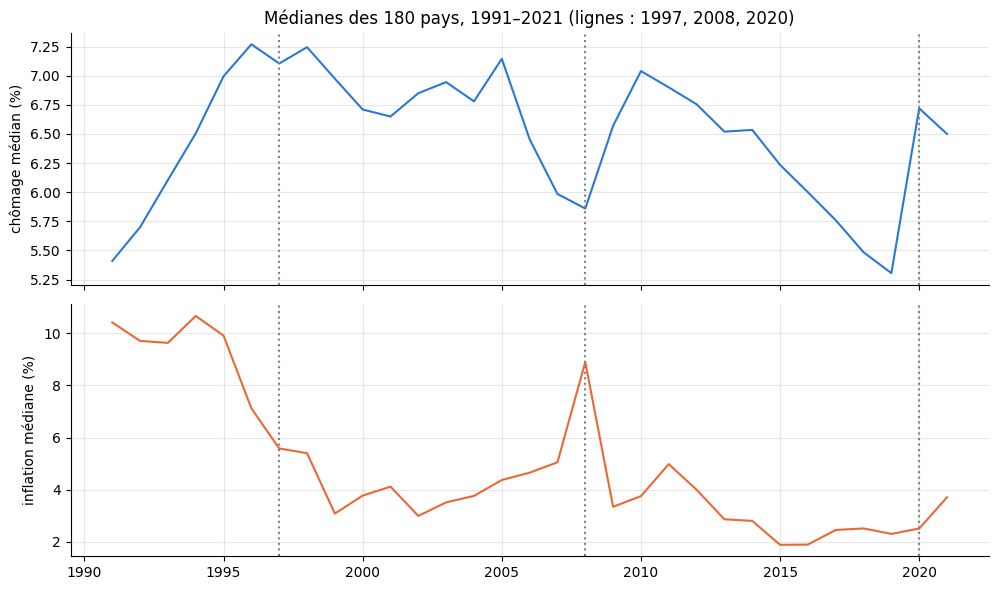

In [15]:
med = panel.groupby("year")[["unemployment", "inflation"]].median()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(med.index, med.unemployment, color="#2a78d6"); a1.set_ylabel("chômage médian (%)")
a2.plot(med.index, med.inflation, color="#eb6834"); a2.set_ylabel("inflation médiane (%)")
for ax in (a1, a2):
    for y, label in {1997: "crise asiatique", 2008: "crise financière", 2020: "COVID-19"}.items():
        ax.axvline(y, color="grey", ls=":")
a1.set_title("Médianes des 180 pays, 1991–2021 (lignes : 1997, 2008, 2020)")
plt.tight_layout(); plt.show()

### 4.5 Comparaison entre régions (2021)

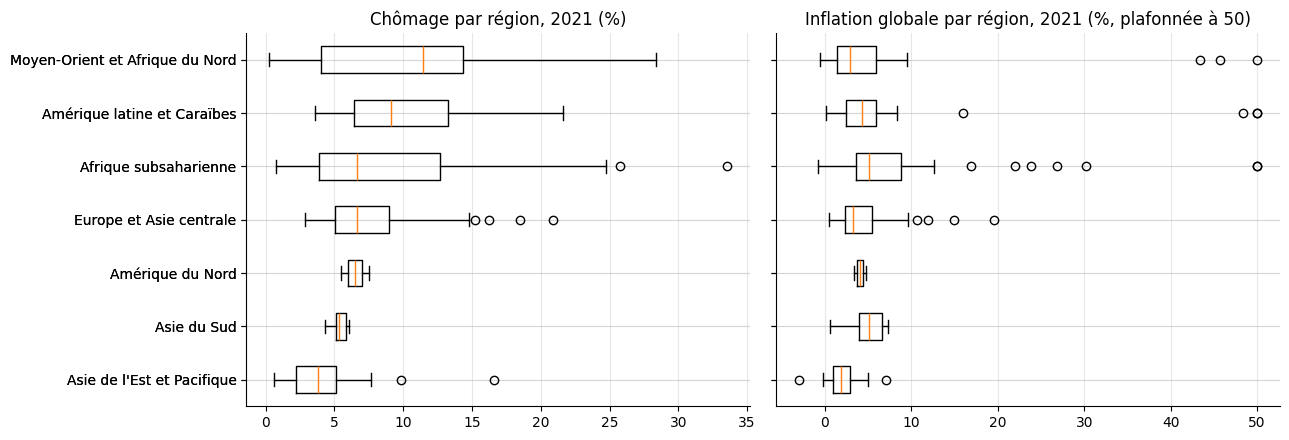

In [16]:
d21 = panel[panel.year == 2021]
order = d21.groupby("region").unemployment.median().sort_values().index
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
a1.boxplot([d21.loc[d21.region == r, "unemployment"] for r in order], vert=False, tick_labels=order)
a1.set(title="Chômage par région, 2021 (%)")
a2.boxplot([d21.loc[d21.region == r, "inflation"].dropna().clip(upper=50) for r in order], vert=False, tick_labels=order)
a2.set(title="Inflation globale par région, 2021 (%, plafonnée à 50)")
plt.tight_layout(); plt.show()

### 4.6 La question centrale : chômage et inflation sont-ils liés ?
Tous pays confondus, il n'y a presque aucun lien. Pays par pays, la majorité a un r négatif (courbe de Phillips),
mais faible : c'est pourquoi le tableau de bord montre la relation pays par pays plutôt qu'un seul chiffre.

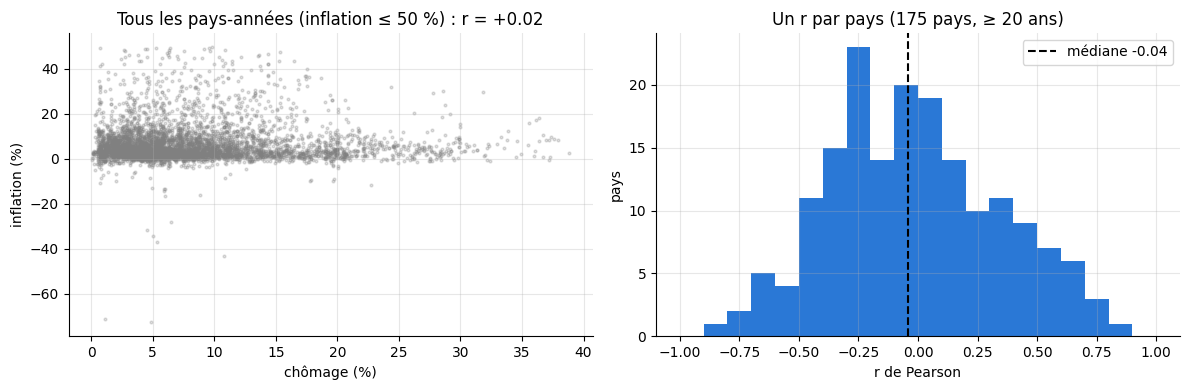

54% des pays ont r < 0


In [17]:
both = panel.dropna(subset=["unemployment", "inflation"])
both = both[both.inflation <= 50]
r_all = both.unemployment.corr(both.inflation)
r_country = (both.groupby("iso3").filter(lambda g: len(g) >= 20)
             .groupby("iso3")[["unemployment", "inflation"]].corr().xs("unemployment", level=1)["inflation"].dropna())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.scatter(both.unemployment, both.inflation, s=4, alpha=0.25, color="grey")
a1.set(title=f"Tous les pays-années (inflation ≤ 50 %) : r = {r_all:+.2f}", xlabel="chômage (%)", ylabel="inflation (%)")
a2.hist(r_country, bins=20, range=(-1, 1), color="#2a78d6")
a2.axvline(r_country.median(), color="k", ls="--", label=f"médiane {r_country.median():+.2f}")
a2.set(title=f"Un r par pays ({len(r_country)} pays, ≥ 20 ans)", xlabel="r de Pearson", ylabel="pays"); a2.legend()
plt.tight_layout(); plt.show()
print(f"{(r_country < 0).mean():.0%} des pays ont r < 0")

## 5. Imputation

Méthode : interpolation linéaire à l'intérieur de chaque pays, **seulement pour les trous de 2 ans ou moins**, entourés
de vraies valeurs. Un trou plus long reste entièrement vide, et on ne prolonge jamais une série avant sa première ou après
sa dernière valeur : l'inflation varie peu d'une année à l'autre, mais combler un long trou reviendrait à inventer des données.

Piège : `interpolate(limit=2)` ne fait **pas** cela. Il remplit au plus 2 années *consécutives*, donc aussi les 2 premières
années d'un trou plus long. On mesure d'abord la taille de chaque trou, puis on ne comble que les petits :

In [18]:
def fill_short_gaps(s, max_gap=2):
    missing = s.isna()
    gap_len = missing.groupby((~missing).cumsum()).transform("sum")  # taille du trou de chaque année manquante
    return s.mask(missing & (gap_len <= max_gap), s.interpolate(limit_area="inside"))

demo = pd.Series([1, None, 3, None, None, None, None, 8], index=range(2000, 2008), dtype=float)
pd.DataFrame({"original": demo, "interpolate(limit=2)": demo.interpolate(limit=2, limit_area="inside"),
              "fill_short_gaps": fill_short_gaps(demo)}).T

,2000,2001,2002,2003,2004,2005,2006,2007
original,1.0,NaN,3.0,NaN,NaN,NaN,NaN,8.0
interpolate(limit=2),1.0,2.0,3.0,4.0,5.0,NaN,NaN,8.0
fill_short_gaps,1.0,2.0,3.0,NaN,NaN,NaN,NaN,8.0


In [19]:
panel = panel.sort_values(["iso3", "year"]).reset_index(drop=True)
before = panel.copy()
panel[INFL_COLS] = panel.groupby("iso3")[INFL_COLS].transform(fill_short_gaps)

pd.DataFrame({
    "manquants avant": before[INFL_COLS].isna().sum(),
    "valeurs imputées": before[INFL_COLS].isna().sum() - panel[INFL_COLS].isna().sum(),
    "manquants après (%)": (panel[INFL_COLS].isna().mean() * 100).round(1),
})

,manquants avant,valeurs imputées,manquants après (%)
inflation,91,0,1.6
food_inflation,731,22,12.7
energy_inflation,1402,20,24.8


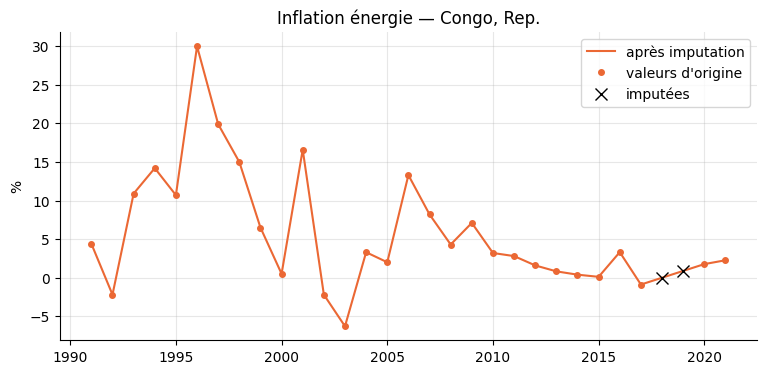

In [20]:
# Exemple : le pays qui a reçu le plus de valeurs d'énergie imputées
imputed = before.energy_inflation.isna() & panel.energy_inflation.notna()
iso = panel.loc[imputed, "iso3"].value_counts().index[0]
c, cb = panel[panel.iso3 == iso], before[before.iso3 == iso]
plt.plot(c.year, c.energy_inflation, color="#eb6834", label="après imputation")
plt.plot(cb.year, cb.energy_inflation, "o", color="#eb6834", ms=4, label="valeurs d'origine")
plt.plot(c.year[imputed[c.index]], c.energy_inflation[imputed[c.index]], "x", color="k", ms=9, label="imputées")
plt.title(f"Inflation énergie — {c.country.iloc[0]}"); plt.ylabel("%"); plt.legend(); plt.show()

In [21]:
panel = panel[["iso3", "country", "region", "income_group", "year", "unemployment"] + INFL_COLS].round(2)
print(panel.shape)
panel.head()

(5580, 9)


,iso3,country,region,income_group,year,unemployment,inflation,food_inflation,energy_inflation
0,AFG,Afghanistan,Moyen-Orient et Afrique du Nord,Faible revenu,1991,10.65,43.80,NaN,NaN
1,AFG,Afghanistan,Moyen-Orient et Afrique du Nord,Faible revenu,1992,10.82,58.19,NaN,NaN
2,AFG,Afghanistan,Moyen-Orient et Afrique du Nord,Faible revenu,1993,10.72,33.99,NaN,NaN
3,AFG,Afghanistan,Moyen-Orient et Afrique du Nord,Faible revenu,1994,10.73,20.01,NaN,NaN
4,AFG,Afghanistan,Moyen-Orient et Afrique du Nord,Faible revenu,1995,11.18,14.00,NaN,NaN


## 6. Regroupement des pays (KMeans)

Objectif : regrouper les pays qui se ressemblent, pour que le public puisse comparer un pays à ses semblables.
Cinq attributs par pays, calculés sur 1991–2021 :

- chômage médian et son écart-type (niveau et volatilité du chômage) ;
- inflation médiane et son écart-type (niveau et volatilité de l'inflation) ;
- r de Phillips du pays (au moins 20 années complètes).

L'inflation est passée en log signé (les hyperinflations écraseraient sinon les distances), puis tout est standardisé.

In [22]:
def stats(g):
    both = g.dropna(subset=["unemployment", "inflation"])
    return pd.Series({
        "unemp_median": g.unemployment.median(), "unemp_std": g.unemployment.std(),
        "infl_median": g.inflation.median(), "infl_std": g.inflation.std(),
        "phillips_r": both.unemployment.corr(both.inflation) if len(both) >= 20 else np.nan,
    })

prof = panel.groupby("iso3").apply(stats, include_groups=False).reset_index()
prof = prof.merge(panel[["iso3", "country", "region", "income_group"]].drop_duplicates(), on="iso3")

feats = prof[["unemp_median", "unemp_std", "infl_median", "infl_std", "phillips_r"]].copy()
for col in ["infl_median", "infl_std"]:
    feats[col] = np.sign(feats[col]) * np.log1p(feats[col].abs())
ok = feats.notna().all(axis=1)
X = StandardScaler().fit_transform(feats[ok])
print(f"{ok.sum()} pays regroupés ({(~ok).sum()} sans assez de données)")

178 pays regroupés (2 sans assez de données)


### 6.1 Choix du nombre de groupes
La silhouette est la plus haute pour k = 2, mais deux groupes ne séparent que « stable / instable ». On retient
**k = 4** : la silhouette reste correcte et les groupes sont interprétables pour le public (voir 6.2).

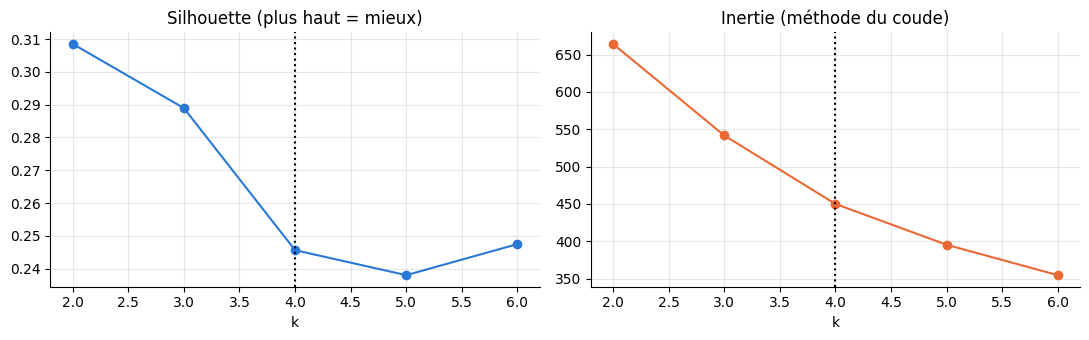

{2: np.float64(0.309), 3: np.float64(0.289), 4: np.float64(0.246), 5: np.float64(0.238), 6: np.float64(0.247)}


In [23]:
ks = range(2, 7)
fits = {k: KMeans(k, n_init=10, random_state=0).fit(X) for k in ks}
sil = [silhouette_score(X, fits[k].labels_) for k in ks]
inertia = [fits[k].inertia_ for k in ks]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(ks, sil, "o-", color="#2a78d6"); a1.set(title="Silhouette (plus haut = mieux)", xlabel="k")
a2.plot(ks, inertia, "o-", color="#eb6834"); a2.set(title="Inertie (méthode du coude)", xlabel="k")
for ax in (a1, a2):
    ax.axvline(4, color="k", ls=":")
plt.tight_layout(); plt.show()
print({k: round(s, 3) for k, s in zip(ks, sil)})

### 6.2 Les quatre profils

In [24]:
prof.loc[ok, "cluster"] = fits[4].labels_

def name_clusters(p):
    """Nom lisible de chaque groupe, d'après ses médianes comparées à la médiane de tous les pays."""
    med = p[["unemp_median", "infl_median", "infl_std"]].median()
    names = {}
    for k, g in p.groupby("cluster"):
        c = g[["unemp_median", "infl_median", "infl_std"]].median()
        infl = ("Inflation élevée et volatile" if c.infl_std > 2 * med.infl_std
                else "Inflation élevée" if c.infl_median > med.infl_median else "Inflation faible")
        names[k] = f"{infl}, {'chômage élevé' if c.unemp_median > med.unemp_median else 'chômage faible'}"
    for k, g in p.groupby("cluster"):  # deux noms identiques -> on les distingue par le signe de r
        if list(names.values()).count(names[k]) > 1:
            names[k] += " (r < 0)" if g.phillips_r.median() < 0 else " (r ≥ 0)"
    return names

prof["profile"] = prof.cluster.map(name_clusters(prof[ok])).fillna("Données insuffisantes")
prof = prof.drop(columns="cluster")

prof.groupby("profile").agg(pays=("iso3", "size"), chômage_médian=("unemp_median", "median"),
                            inflation_médiane=("infl_median", "median"), r_médian=("phillips_r", "median"),
                            exemples=("country", lambda s: ", ".join(s.head(3)))).round(2).sort_values("pays", ascending=False)

,pays,chômage_médian,inflation_médiane,r_médian,exemples
profile,,,,,
"Inflation faible, chômage faible",63,4.99,2.20,-0.21,"United Arab Emirates, Australia, Austria"
"Inflation élevée, chômage faible",58,4.68,7.28,0.06,"Afghanistan, Burundi, Bangladesh"
"Inflation faible, chômage élevé",29,17.87,3.04,-0.01,"Albania, Bosnia and Herzegovina, Barbados"
"Inflation élevée et volatile, chômage élevé",28,8.56,9.54,-0.29,"Angola, Argentina, Armenia"
Données insuffisantes,2,7.82,25.69,NaN,"South Sudan, Timor-Leste"


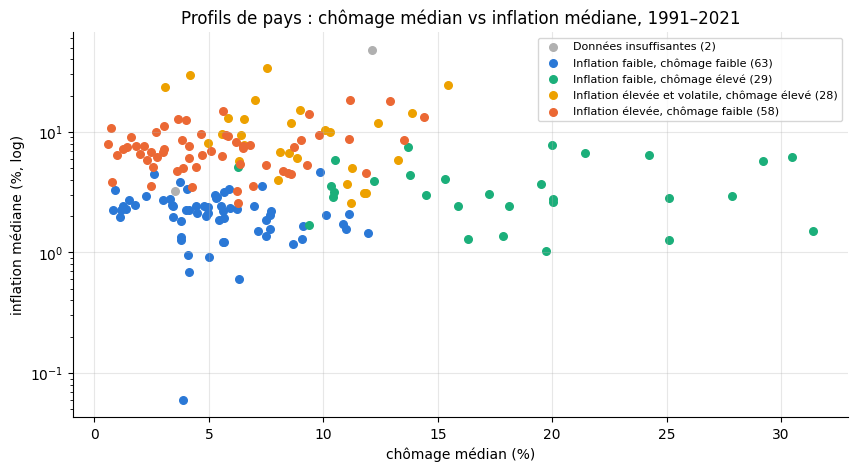

In [25]:
colors = dict(zip(prof.profile.value_counts().index, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b0b0b0"]))
fig, ax = plt.subplots(figsize=(10, 5))
for name, g in prof[prof.infl_median > 0].groupby("profile"):
    ax.scatter(g.unemp_median, g.infl_median, s=30, color=colors[name], label=f"{name} ({len(g)})")
ax.set_yscale("log")
ax.set(title="Profils de pays : chômage médian vs inflation médiane, 1991–2021",
       xlabel="chômage médian (%)", ylabel="inflation médiane (%, log)")
ax.legend(fontsize=8); plt.show()

## 7. Vérification

Le tableau de bord lit `data/clean/panel.csv` et `data/clean/countries.csv`, produits par `prepare_data.py`.
On vérifie que ce notebook obtient exactement les mêmes tables (sans réécrire les fichiers).

In [26]:
ref_panel = pd.read_csv(CLEAN / "panel.csv")
ref_prof = pd.read_csv(CLEAN / "countries.csv")
pd.testing.assert_frame_equal(panel.reset_index(drop=True), ref_panel, check_dtype=False)
pd.testing.assert_frame_equal(prof.round(3)[ref_prof.columns], ref_prof, check_dtype=False)
print(f"OK : panel.csv ({len(ref_panel)} lignes) et countries.csv ({len(ref_prof)} pays) identiques à prepare_data.py")

OK : panel.csv (5580 lignes) et countries.csv (180 pays) identiques à prepare_data.py
